In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../donnee/cdr_nettoye.csv")
cellules = pd.read_csv("../donnee/cellules.csv")

Matplotlib is building the font cache; this may take a moment.


In [6]:
df["horodatage"] = pd.to_datetime(df["horodatage"])
df["type_service"] = df["type_service"].str.lower()
df["heure"] = df["horodatage"].dt.hour

print(df.columns.tolist())
print(cellules.columns.tolist())

['id_cdr', 'id_abonne', 'horodatage', 'type_service', 'direction', 'duree_sec', 'volume_mo', 'id_cellule', 'id_correspondant', 'statut', 'cout_gnf', 'heure']
['id_cellule', 'zone', 'region', 'type_zone', 'technologie', 'latitude', 'longitude']


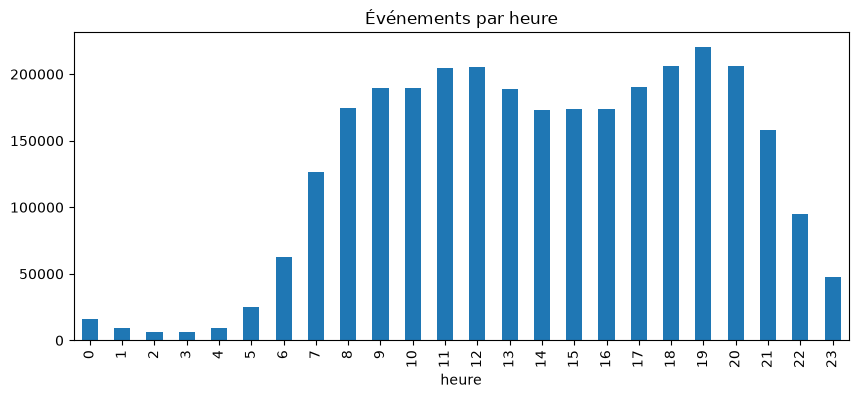

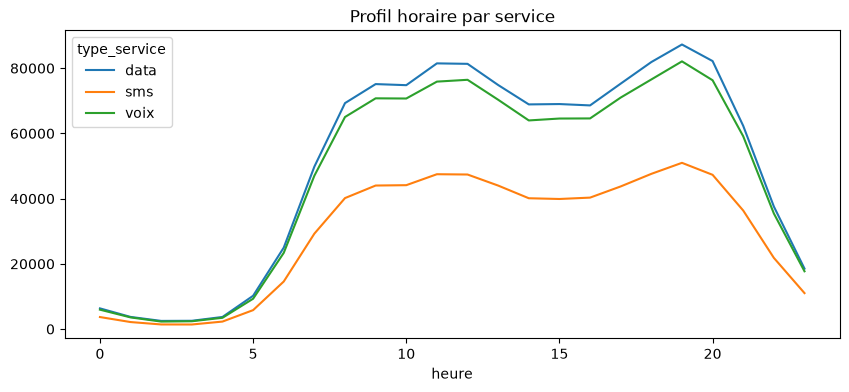

In [ ]:
# Profils d'événements horaires
profil = df.groupby("heure").size()
profil.plot(kind="bar", title="Événements par heure", figsize=(10, 4))
plt.show()

df.groupby(["heure", "type_service"]).size().unstack().plot(figsize=(10, 4))
plt.title("Profil horaire par service")
plt.show()

In [8]:
comparaison = df.groupby("type_service").agg(
    nb_evenements=("id_cdr", "count"),
    duree_moy_sec=("duree_sec", "mean"),
    volume_total_mo=("volume_mo", "sum"),
    revenu_total_gnf=("cout_gnf", "sum"),
    cout_moyen_gnf=("cout_gnf", "mean"),
)
comparaison

,nb_evenements,duree_moy_sec,volume_total_mo,revenu_total_gnf,cout_moyen_gnf
type_service,,,,,
data,1212183,319.537185,28969784.23,218762309,180.469705
sms,706891,0.000000,0.00,19284900,27.281292
voix,1137855,129.773038,0.00,83521169,73.402296


Lignes sans zone : 0


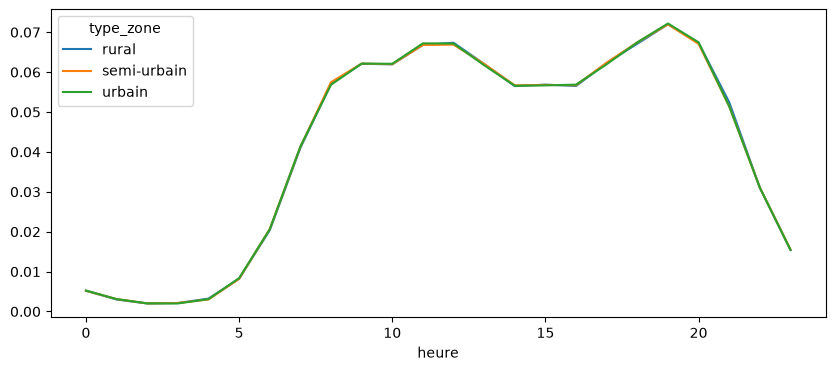

In [16]:
df_zone = df.merge(cellules[["id_cellule", "type_zone"]], on="id_cellule", how="left")
print("Lignes sans zone :", df_zone["type_zone"].isna().sum())

df_zone.groupby(["type_zone", "type_service"]).agg(
    nb=("id_cdr", "count"),
    revenu=("cout_gnf", "sum"),
    cout_moyen=("cout_gnf", "mean"),
)

# Profil horaire en pourcentage, pour comparer les trois zones
pd.crosstab(df_zone["heure"], df_zone["type_zone"], normalize="columns").plot(figsize=(10, 4))
plt.show()

In [19]:
print(df.columns.tolist())

['id_cdr', 'id_abonne', 'horodatage', 'type_service', 'direction', 'duree_sec', 'volume_mo', 'id_cellule', 'id_correspondant', 'statut', 'cout_gnf', 'heure']


Taux d'échec global : 3.32 %
type_service
data    3.14
sms     3.49
voix    3.42
Name: echec, dtype: float64
type_zone
rural          4.96
semi-urbain    3.82
urbain         2.43
Name: echec, dtype: float64


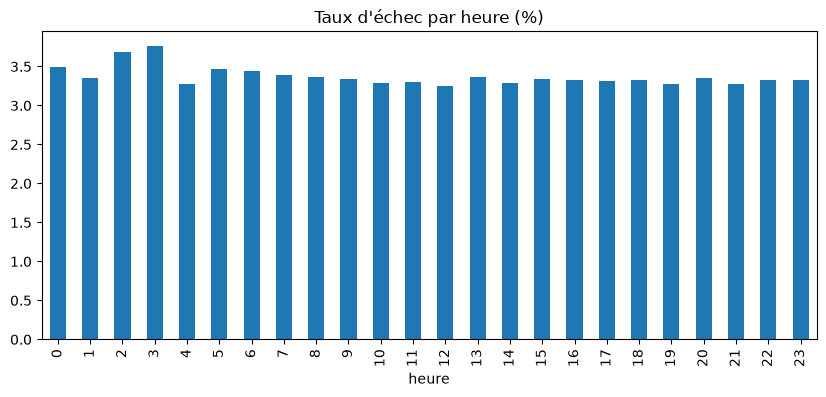

In [23]:
df_zone["echec"] = df_zone["statut"] == "echec"

print("Taux d'échec global : %.2f %%" % (df_zone["echec"].mean() * 100))
print((df_zone.groupby("type_service")["echec"].mean() * 100).round(2))
print((df_zone.groupby("type_zone")["echec"].mean() * 100).round(2))

(df_zone.groupby("heure")["echec"].mean() * 100).plot(kind="bar", figsize=(10, 4))
plt.title("Taux d'échec par heure (%)")
plt.show()

In [24]:
import logging